# Tuning Logistic Regression

Saurya Jonchhe

I searched the logistic regression grid and the SGD grid from the README. Both use 3-fold CV on the training rows and pick the best phishing F1. Then I compare the two winners on dev and keep whichever has the higher dev F1. Test is for the conclusion.

The README calls SGDClassifier the mini-batch version, but its fit() updates one row at a time. I also wrote a small logistic regression that averages the gradient over batches of 256. That one is extra. It is not part of the two searches.

Run the cells from the project folder.


In [1]:
import warnings
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.special import expit
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.class_weight import compute_sample_weight
from dataset_preparation import prepare_datasets, build_preparation_pipeline
%matplotlib inline
print("scikit-learn:", sklearn.__version__)
data = prepare_datasets()
print("Training rows:", len(data["y_train"]))
print("Dev rows:", len(data["y_dev"]))
print("Not scoring the test split.")

scikit-learn: 1.6.1
Training rows: 69138
Dev rows: 23046
Not scoring the test split.


## The search

Each model sits after the shared prep pipeline. I pass the raw training table into GridSearchCV, so the median and the scaler get fit inside each fold. cv=3 and random_state=42.

The regular logistic grid is 16 settings. The SGD grid is 6. The winner gets refit on all of the training rows. I do not use dev to pick a setting inside either search.

One L1 fold took more than 15 minutes when I left max_iter at 2000. For the search I dropped that to max_iter=100 and tol=1e-3 so it would finish. I still try every C, penalty, solver, and class weight, on all three folds. Some of the settings that lost might not have fully converged, so I do not trust their order that much. After the search I refit the winner with max_iter=2000 and tol=1e-4 and check that it actually converged. SGD stays on the README settings.


In [2]:
model = LogisticRegression(max_iter=100, tol=1e-3, random_state=42)
param_grid = [
    {"model__penalty": ["l2"], "model__solver": ["lbfgs"],
     "model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]},
    {"model__penalty": ["l1"], "model__solver": ["liblinear"],
     "model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]},
]
sgd_model = SGDClassifier(loss="log_loss", penalty="l2", learning_rate="optimal",
                          max_iter=1000, random_state=42)
sgd_grid = {"model__alpha": [0.00001, 0.0001, 0.001],
            "model__class_weight": [None, "balanced"]}

def run_search(estimator, grid):
    full_pipeline = Pipeline([("prepare", build_preparation_pipeline()), ("model", estimator)])
    search = GridSearchCV(full_pipeline, grid, scoring="f1", cv=3,
                          n_jobs=4, error_score="raise", return_train_score=True)
    start = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        search.fit(data["X_train"], data["y_train"])
    print("Elapsed seconds:", round(perf_counter() - start, 2))
    print("Best parameters:", search.best_params_)
    print("Best mean CV F1:", round(search.best_score_, 4))
    convergence = [str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning)]
    print("Convergence warnings:", sorted(set(convergence)) or "None")
    print("Other warnings:", sorted(set(str(w.message) for w in caught
                                         if not issubclass(w.category, ConvergenceWarning))) or "None")
    winner_iterations = search.best_estimator_.named_steps["model"].n_iter_
    print("Selected estimator iterations:", winner_iterations)
    if isinstance(estimator, LogisticRegression):
        # The search used a short max_iter. Refit the winner with 2000.
        search.best_estimator_.set_params(model__max_iter=2000, model__tol=1e-4)
        with warnings.catch_warnings(record=True) as final_warnings:
            warnings.simplefilter("always")
            search.best_estimator_.fit(data["X_train"], data["y_train"])
        print("Full-budget refit warnings:", sorted(set(str(w.message) for w in final_warnings)) or "None")
        final_convergence = [w for w in final_warnings if issubclass(w.category, ConvergenceWarning)]
        assert not final_convergence, "The selected full-budget model did not converge."
    table = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    display(table[["rank_test_score", "mean_train_score", "mean_test_score", "std_test_score", "params"]].head(6))
    return search

standard_search = run_search(model, param_grid)

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS42

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encounte

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encounte

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: invalid value encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encoun

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklea

...

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklea

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/

Elapsed seconds: 92.06
Best parameters: {'model__C': 10.0, 'model__class_weight': None, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best mean CV F1: 0.8265
Convergence warnings: None
Other warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']
Selected estimator iterations: [29]
Full-budget refit warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
6,1,0.827473,0.826456,0.003560,"{'model__C': 10.0, 'model__class_weight': None..."
12,2,0.828085,0.826359,0.003824,"{'model__C': 1.0, 'model__class_weight': None,..."
4,3,0.826997,0.825905,0.004076,"{'model__C': 1.0, 'model__class_weight': None,..."
10,4,0.825171,0.824096,0.003639,"{'model__C': 0.1, 'model__class_weight': None,..."
2,5,0.819589,0.819853,0.001941,"{'model__C': 0.1, 'model__class_weight': None,..."
14,6,0.808990,0.809897,0.026662,"{'model__C': 10.0, 'model__class_weight': None..."


In [3]:
sgd_search = run_search(sgd_model, sgd_grid)

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklea

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklea

/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saurya/DS420Project/.venv/lib/python3.9/site-packages/sklea

Elapsed seconds: 1.07
Best parameters: {'model__alpha': 0.0001, 'model__class_weight': None}
Best mean CV F1: 0.8233
Convergence warnings: None
Other warnings: None
Selected estimator iterations: 18


,rank_test_score,mean_train_score,mean_test_score,std_test_score,params
2,1,0.824436,0.823326,0.004894,"{'model__alpha': 0.0001, 'model__class_weight'..."
4,2,0.803965,0.804376,0.002427,"{'model__alpha': 0.001, 'model__class_weight':..."
0,3,0.791267,0.787690,0.025752,"{'model__alpha': 1e-05, 'model__class_weight':..."
3,4,0.783524,0.781504,0.009367,"{'model__alpha': 0.0001, 'model__class_weight'..."
5,5,0.760590,0.760188,0.002876,"{'model__alpha': 0.001, 'model__class_weight':..."
1,6,0.746106,0.746246,0.017607,"{'model__alpha': 1e-05, 'model__class_weight':..."


## Dev comparison

I report phishing precision, recall, and F1, plus accuracy and ROC AUC. ROC AUC uses the decision scores. I left the threshold alone. Warnings get printed, and I check that the scores are finite. Dev is how I choose between the two winners, so this is not a clean final number.


In [4]:
def evaluate(estimator):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        predicted = estimator.predict(data["X_dev"])
        scores = estimator.decision_function(data["X_dev"])
    assert np.isfinite(scores).all()
    X = estimator.named_steps["prepare"].transform(data["X_dev"])
    fitted = estimator.named_steps["model"]
    direct = np.einsum("ij,j->i", X, fitted.coef_[0]) + fitted.intercept_[0]
    assert np.allclose(scores, direct, rtol=1e-10, atol=1e-10)
    print("Evaluation warnings:", sorted(set(str(w.message) for w in caught)) or "None")
    return {"Accuracy": accuracy_score(data["y_dev"], predicted),
            "Phishing precision": precision_score(data["y_dev"], predicted, zero_division=0),
            "Phishing recall": recall_score(data["y_dev"], predicted, zero_division=0),
            "Phishing F1": f1_score(data["y_dev"], predicted, zero_division=0),
            "ROC AUC": roc_auc_score(data["y_dev"], scores)}, predicted, scores

candidates = {"Standard logistic regression": standard_search.best_estimator_,
              "SGD logistic regression": sgd_search.best_estimator_}
results, predictions, rankings = {}, {}, {}
for name, estimator in candidates.items():
    results[name], predictions[name], rankings[name] = evaluate(estimator)
dev_results = pd.DataFrame(results).T
display(dev_results.round(4))
winner_name = dev_results["Phishing F1"].idxmax()
best_model = candidates[winner_name]
print("Selected search winner:", winner_name)

Evaluation warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']
Evaluation warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']


,Accuracy,Phishing precision,Phishing recall,Phishing F1,ROC AUC
Standard logistic regression,0.9532,0.9028,0.7562,0.8230,0.976
SGD logistic regression,0.9496,0.8892,0.7426,0.8093,0.975


Selected search winner: Standard logistic regression


## Mini-batch gradient descent

For an actual batch update I average the weighted logistic loss over 256 rows, add L2, and take one step per batch. The intercept is not regularized. Learning rate is 0.01 for 100 epochs, shuffled with seed 42. I set those before looking at dev.

Alpha and the class weight come from the SGD winner. This is just to show a real mini-batch update. It is not a third search. I track the training loss so I can see if it is going down.


Evaluation warnings: ['divide by zero encountered in matmul', 'invalid value encountered in matmul', 'overflow encountered in matmul']


,Accuracy,Phishing precision,Phishing recall,Phishing F1,ROC AUC
Explicit mini-batch,0.9469,0.893,0.717,0.7954,0.972


Training objective, first and last epoch: 0.37999 0.1464


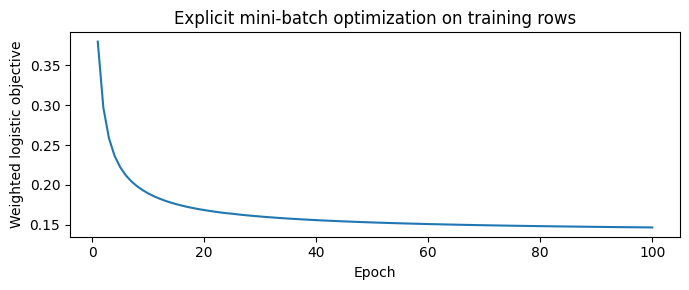

In [5]:
preprocessor = clone(build_preparation_pipeline())
X_mb = preprocessor.fit_transform(data["X_train"])
y_mb = data["y_train"].to_numpy(dtype=float)
alpha = sgd_search.best_params_["model__alpha"]
class_weight = sgd_search.best_params_["model__class_weight"]
weights = compute_sample_weight(class_weight, y_mb)
w = np.zeros(X_mb.shape[1])
b = 0.0
rng = np.random.RandomState(42)
batch_size, learning_rate, epochs = 256, 0.01, 100
loss_history = []
for epoch in range(epochs):
    order = rng.permutation(len(y_mb))
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        X_batch, y_batch = X_mb[idx], y_mb[idx]
        logits = np.einsum("ij,j->i", X_batch, w) + b
        residual = (expit(logits) - y_batch) * weights[idx]
        grad = np.einsum("ij,i->j", X_batch, residual) / len(idx) + alpha * w
        w -= learning_rate * grad
        b -= learning_rate * residual.mean()
    logits = np.einsum("ij,j->i", X_mb, w) + b
    loss = np.mean(weights * (np.logaddexp(0, logits) - y_mb * logits)) + 0.5 * alpha * np.dot(w, w)
    assert np.isfinite(loss)
    loss_history.append(loss)

# Stick the weights on a sklearn classifier so I can score it the same way.
mb_classifier = SGDClassifier(loss="log_loss", random_state=42)
mb_classifier.classes_ = np.array([0, 1])
mb_classifier.coef_ = w.reshape(1, -1)
mb_classifier.intercept_ = np.array([b])
mb_classifier.n_features_in_ = X_mb.shape[1]
mini_batch_model = Pipeline([("prepare", preprocessor), ("model", mb_classifier)])
mb_metrics, mb_predictions, mb_scores = evaluate(mini_batch_model)
display(pd.DataFrame({"Explicit mini-batch": mb_metrics}).T.round(4))
print("Training objective, first and last epoch:", round(loss_history[0], 5), round(loss_history[-1], 5))
plt.figure(figsize=(7, 3))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Weighted logistic objective")
plt.title("Explicit mini-batch optimization on training rows")
plt.tight_layout()
plt.show()

## Mistakes

Confusion matrix rows are the true labels. False negatives are missed phishing URLs, false positives are benign URLs it flagged. ROC AUC is the ranking. F1 is just the default cutoff.


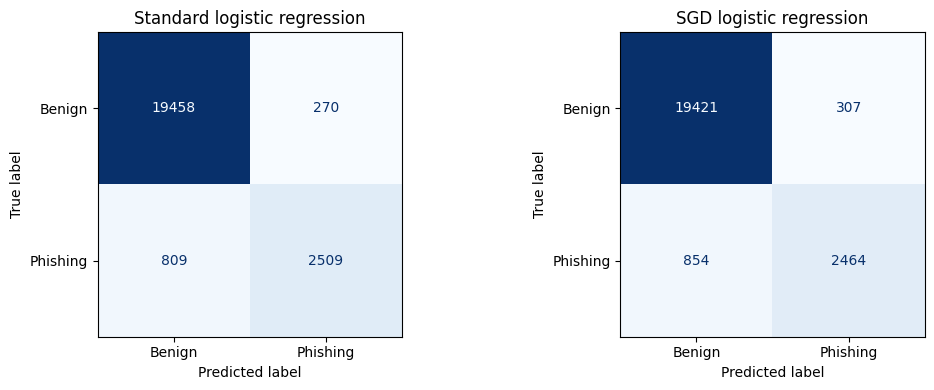

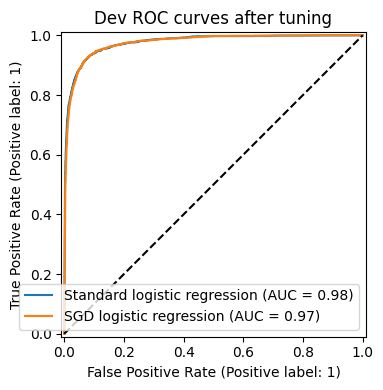

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, candidates):
    ConfusionMatrixDisplay.from_predictions(data["y_dev"], predictions[name],
        labels=[0, 1], display_labels=["Benign", "Phishing"], values_format="d",
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
for name in candidates:
    RocCurveDisplay.from_predictions(data["y_dev"], rankings[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Dev ROC curves after tuning")
plt.tight_layout()
plt.show()

## Which one I am keeping

The model below is fit on train only. I did not score test. My first L1 model had a dev F1 of 0.7795, so that number is just the before-tuning score.


In [7]:
selected = dev_results.loc[winner_name]
selected_search = standard_search if winner_name == "Standard logistic regression" else sgd_search
display(Markdown(
    f"{winner_name} is the one I am keeping. On dev, phishing F1 is {selected['Phishing F1']:.4f}, "
    f"precision {selected['Phishing precision']:.4f}, recall {selected['Phishing recall']:.4f}, "
    f"accuracy {selected['Accuracy']:.4f}, and ROC AUC {selected['ROC AUC']:.4f}. "
    f"CV F1 was {selected_search.best_score_:.4f}. "
    f"That is {selected['Phishing F1'] - 0.7795:+.4f} compared with my first L1 model. "
    f"The mini-batch version I wrote only got dev F1 {mb_metrics['Phishing F1']:.4f}."
))
print("Final search parameters:", selected_search.best_params_)
print("Fitted model is saved as best_model.")

Standard logistic regression is the one I am keeping. On dev, phishing F1 is 0.8230, precision 0.9028, recall 0.7562, accuracy 0.9532, and ROC AUC 0.9760. CV F1 was 0.8265. That is +0.0435 compared with my first L1 model. The mini-batch version I wrote only got dev F1 0.7954.

Final search parameters: {'model__C': 10.0, 'model__class_weight': None, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Fitted model is saved as best_model.


F1 is the balance between missed phishing URLs and false alarms. Recall still matters, because missing a phishing site is worse than a false alarm. We should put this next to the tuned tree and the tuned SVM before anyone looks at test. The CV scores and the dev scores are not test scores.
